# Plánovač letu, pokročilá verze: pokrytí snímky, sledování terénu, vítr a baterie

[![Otevřít v Google Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/OpenSkyLab-space/notebooks/blob/main/flight_planner_pro_cs.ipynb)

**OpenSkyLab · notebook k vizuálu** [Plánovač letu dronu](https://openskylab.space/edu_viz_flight_planner.html) · [English version](flight_planner_pro_en.ipynb)

Pokročilá verze notebooku k plánování letu. Na zalesněném svahu údolí Vltavy u Roztok porovnáš tři způsoby, jak držet výšku: stálou nad místem vzletu, sledování terénu z DMR 5G a sledování povrchu korun z DMP 1G. Pro každý spočítáš, na kolika snímcích je každý bod vidět, jaký je odstup od stromů a jak rychle by dron musel stoupat. Pak podle dnešní předpovědi větru vybereš směr linek a rozdělíš misi na lety po jedné baterii.

**Cíl:** spočítat pokrytí území snímky a odstup od povrchu pro tři režimy výšky, určit potřebné vyhlazení výškového profilu podle rychlosti stoupání, najít nejrychlejší směr linek při skutečném větru a rozdělit misi na lety tak, aby na každý návrat zbyla energie.

**Data:** DMR 5G (terén) a DMP 1G (povrch včetně vegetace a budov) z ČÚZK, služby ImageServer, buňka 2 m, území 1,2 × 0,8 km na levém svahu údolí Vltavy u Roztok; hodinová předpověď větru v 80 m z Open-Meteo na dnešní den; parametry dronu a kamery Mavic 3E z technického listu výrobce. DMP 1G vznikl z leteckého laserového skenování v letech 2009–2013, takže stromy od té doby mohly vyrůst nebo být pokáceny. Model pokrytí předpokládá kameru mířící kolmo dolů a nepočítá se zákryty (koruna zakryje terén pod sebou), čas otočky je orientační.

**Úkoly:** pět. Odpovědi piš do buněk *Tvoje odpověď* pod úkoly. Řádky označené `# ◀ parametr` můžeš měnit a buňku spustit znovu (Shift + Enter).

**Čas:** asi 60 min. Potřebuješ Google účet (Colab); nic se neinstaluje do počítače. Buňky spouštěj popořadě shora dolů.

## 1. Příprava

In [1]:
%pip install -q rasterio

Note: you may need to restart the kernel to use updated packages.


In [2]:
import time, requests
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import rasterio
from pyproj import Transformer
from scipy.ndimage import maximum_filter, uniform_filter1d

def cuzk_raster(service, x0, y0, x1, y1, res=2.0):
    """Výřez rastru ČÚZK (dmr5g, dmp1g, dmp_obrazova_korelace) v S-JTSK (EPSG:5514), výšky v Bpv.
    Vrací pole výšek (řádek 0 = sever) a jeho transformaci."""
    nx, ny = int(round((x1 - x0) / res)), int(round((y1 - y0) / res))
    url = f"https://ags.cuzk.cz/arcgis2/rest/services/{service}/ImageServer/exportImage"
    params = {"bbox": f"{x0},{y0},{x1},{y1}", "bboxSR": 5514, "imageSR": 5514, "size": f"{nx},{ny}",
              "format": "tiff", "pixelType": "F32", "interpolation": "RSP_BilinearInterpolation", "f": "image"}
    for attempt in range(4):
        r = requests.get(url, params=params, timeout=120)
        if r.ok and r.headers.get("content-type", "").startswith("image"):
            break
        time.sleep(3 * (attempt + 1))
    r.raise_for_status()
    with rasterio.MemoryFile(r.content) as mem, mem.open() as ds:
        return ds.read(1).astype(float), ds.transform

def open_meteo(params, tries=6):
    """Dotaz na Open-Meteo; při chybě nebo vyčerpaném limitu to zkusí znovu."""
    for i in range(tries):
        try:
            r = requests.get("https://api.open-meteo.com/v1/forecast", params=params, timeout=60)
            if r.ok:
                return r.json()
            reason = r.json().get("reason", r.status_code)
        except requests.RequestException as e:
            reason = type(e).__name__
        print("Open-Meteo:", reason, "– zkusím znovu"); time.sleep(5 * (i + 1))
    raise RuntimeError("Open-Meteo neodpovídá, spusť buňku za chvíli znovu.")

## 2. Terén, povrch a plán linek

DMR 5G popisuje holý terén, DMP 1G povrch, který vidí kamera: koruny stromů a střechy. Jejich rozdíl je výška vegetace a budov. Plán je stejný jako v základní verzi: kamera Mavic 3E, linky východ–západ, místo vzletu na západním okraji.

terén 175–257 m n. m., povrch 175–276 m n. m., místo vzletu 225 m n. m.
vegetace nebo budovy vyšší než 2 m na 83% území, medián jejich výšky 14.4 m, 99. percentil 26.2 m


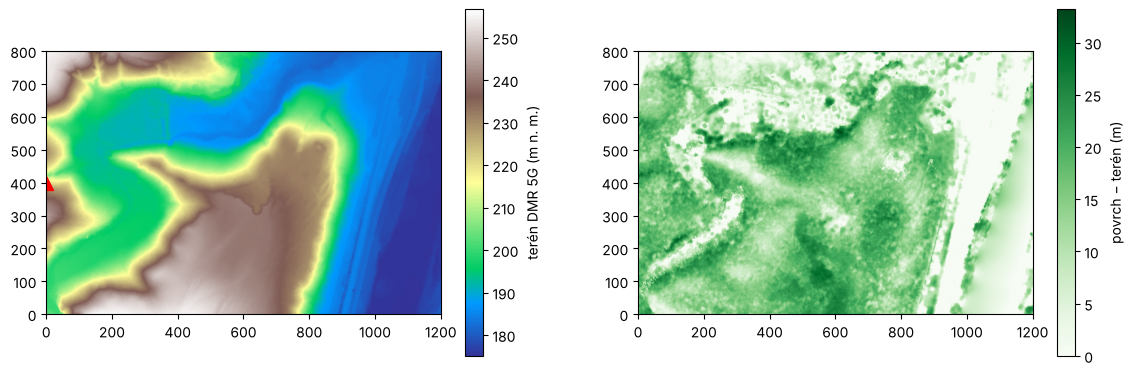

In [3]:
LON, LAT = 14.392, 50.152            # ◀ parametr: střed území (levý svah údolí Vltavy u Roztok)
W, Hh, RES = 1200, 800, 2.0          # šířka (V–Z) a výška (S–J) území v m, buňka 2 m
cx, cy = Transformer.from_crs(4326, 5514, always_xy=True).transform(LON, LAT)
box = (cx - W / 2, cy - Hh / 2, cx + W / 2, cy + Hh / 2)
dmr, _ = cuzk_raster("dmr5g", *box, res=RES)       # terén
dmp, _ = cuzk_raster("dmp1g", *box, res=RES)       # povrch včetně stromů a budov
veg = np.clip(dmp - dmr, 0, None)                   # výška vegetace a budov nad terénem
z_takeoff = float(np.median(dmr[:, :10]))           # místo vzletu na západním okraji
HOME = (0.0, Hh / 2)                                # ◀ parametr: poloha místa vzletu v území (x, y v m)
xs = np.arange(dmr.shape[1]) * RES + RES / 2        # souřadnice středů buněk (x na východ, y na sever)
ys = Hh - np.arange(dmr.shape[0]) * RES - RES / 2
print(f"terén {dmr.min():.0f}–{dmr.max():.0f} m n. m., povrch {dmp.min():.0f}–{dmp.max():.0f} m n. m., místo vzletu {z_takeoff:.0f} m n. m.")
print(f"vegetace nebo budovy vyšší než 2 m na {np.mean(veg > 2):.0%} území, medián jejich výšky {np.median(veg[veg > 2]):.1f} m, 99. percentil {np.percentile(veg, 99):.1f} m")
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for a, arr, lbl, cm in [(ax[0], dmr, "terén DMR 5G (m n. m.)", "terrain"), (ax[1], veg, "povrch − terén (m)", "Greens")]:
    im = a.imshow(arr, cmap=cm, extent=(0, W, 0, Hh)); fig.colorbar(im, ax=a, label=lbl)
ax[0].plot(*HOME, "r^", ms=10); plt.show()

In [4]:
CAM = dict(sw=17.3, sh=13.0, pw=5280, ph=3956, f=12.3)   # Mavic 3E: čip (mm), pixely, ohnisko (mm)
H0 = 80.0             # ◀ parametr: výška letu (m) nad místem vzletu, nad terénem nebo nad povrchem podle režimu
FO, SO = 0.80, 0.70   # ◀ parametr: podélný a příčný překryv
V = 8.0               # ◀ parametr: rychlost vůči vzduchu (m/s)
SMOOTH = 40           # ◀ parametr: délka vyhlazení výškového profilu linky (m) při sledování terénu a povrchu
p, f = CAM["sw"] / CAM["pw"] / 1000, CAM["f"] / 1000
gsd0 = H0 * p / f
base = (1 - FO) * CAM["ph"] * gsd0                  # vzdálenost snímků podél linky (krátká strana snímku podél)
spacing = (1 - SO) * CAM["pw"] * gsd0               # rozestup linek (dlouhá strana napříč)
line_y = np.arange(0, Hh + spacing / 2, spacing)    # linky V–Z
shot_x = np.arange(0, W + base / 2, base)
xline = np.arange(0, W + RES / 2, RES)

def sample(arr, x, y):
    i = np.clip(((Hh - y) / RES).astype(int), 0, arr.shape[0] - 1)
    j = np.clip((x / RES).astype(int), 0, arr.shape[1] - 1)
    return arr[i, j]

def altitude(mode, y, smooth=SMOOTH):
    """Nadmořská výška dronu podél linky y v bodech xline."""
    if mode == "stálá":
        return np.full_like(xline, z_takeoff + H0)
    ref = sample(dmr if mode == "terén" else dmp, xline, np.full_like(xline, y))
    n = max(int(smooth / RES), 1)
    if n > 1:                                         # nejdřív maximum (aby dron nepodletěl vrchol), pak průměr
        ref = uniform_filter1d(maximum_filter(ref, size=n, mode="nearest"), size=n, mode="nearest")
    return ref + H0

print(f"GSD při výšce {H0:.0f} m: {gsd0 * 100:.2f} cm/px, báze {base:.1f} m, rozestup linek {spacing:.1f} m, {len(line_y)} linek × {len(shot_x)} snímků")
print(f"teoreticky na rovině: každý bod na {1 / ((1 - FO) * (1 - SO)):.1f} snímcích")

GSD při výšce 80 m: 2.13 cm/px, báze 16.9 m, rozestup linek 33.8 m, 25 linek × 72 snímků
teoreticky na rovině: každý bod na 16.7 snímcích


## 3. Na kolika snímcích je každý bod vidět

Pro každý snímek spočítáme, které buňky povrchu leží v jeho záběru. Záběr se zvětšuje s výškou kamery nad tím, co vidí, takže koruny blíž ke kameře pokryje menší výřez. Porovnáme tři režimy: **stálá** výška H0 nad místem vzletu, **terén** (H0 nad DMR 5G) a **povrch** (H0 nad DMP 1G). U sledování se výškový profil linky vyhlazuje (`SMOOTH`).

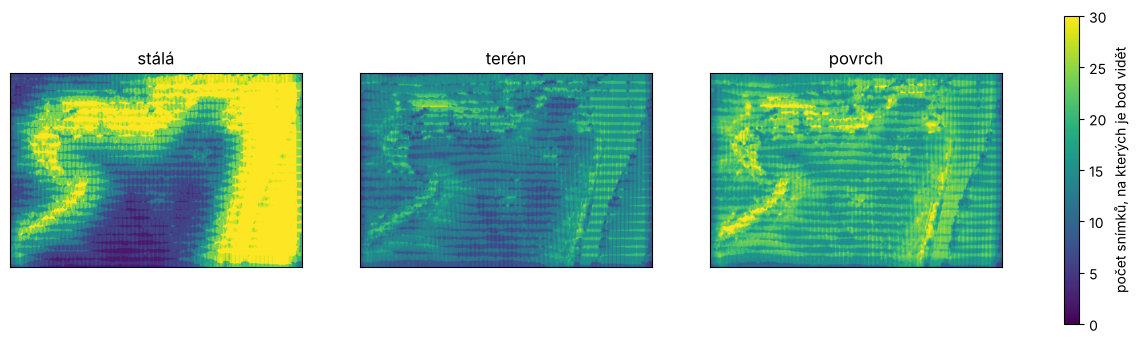

,medián snímků na bod,podíl bodů s < 9 snímky,GSD na povrchu 5 % (cm),GSD na povrchu 95 % (cm),nejmenší odstup od povrchu (m)
stálá,20.0,0.21,1.09,3.34,29.13
terén,13.0,0.10,1.55,2.18,51.83
povrch,20.0,0.00,2.14,2.46,79.54


In [5]:
MODES = ["stálá", "terén", "povrch"]   # stálá výška nad místem vzletu, sledování DMR 5G, sledování DMP 1G
hx, hy = CAM["sh"] / CAM["f"] / 2, CAM["sw"] / CAM["f"] / 2   # poloviční záběr na 1 m výšky: podél linky (x), napříč (y)
cov, rows = {}, {}
for mode in MODES:
    cnt = np.zeros(dmr.shape, dtype=np.int16)
    agl_all, clear = [], np.inf
    for y in line_y:
        zl = altitude(mode, y)
        surf = sample(dmp, xline, np.full_like(xline, y))
        agl_all.append(zl - surf); clear = min(clear, float((zl - surf).min()))
        for x in shot_x:
            zc = float(np.interp(x, xline, zl))
            ext = zc - dmp.min()
            i0, i1 = int(max((Hh - y - ext * hy) / RES, 0)), int(min((Hh - y + ext * hy) / RES + 1, dmr.shape[0]))
            j0, j1 = int(max((x - ext * hx) / RES, 0)), int(min((x + ext * hx) / RES + 1, dmr.shape[1]))
            h = zc - dmp[i0:i1, j0:j1]                 # výška kamery nad viděným povrchem
            cnt[i0:i1, j0:j1] += (np.abs(xs[j0:j1][None, :] - x) <= h * hx) & (np.abs(ys[i0:i1][:, None] - y) <= h * hy) & (h > 0)
    cov[mode] = cnt
    inner = cnt[20:-20, 20:-20]                        # bez okrajového pásu 40 m
    agl_all = np.concatenate(agl_all)
    rows[mode] = {"medián snímků na bod": np.median(inner), "podíl bodů s < 9 snímky": np.mean(inner < 9),
                  "GSD na povrchu 5 % (cm)": np.percentile(agl_all, 5) * p / f * 100, "GSD na povrchu 95 % (cm)": np.percentile(agl_all, 95) * p / f * 100,
                  "nejmenší odstup od povrchu (m)": clear}
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for a, mode in zip(ax, MODES):
    im = a.imshow(cov[mode], cmap="viridis", vmin=0, vmax=30, extent=(0, W, 0, Hh)); a.set_title(mode); a.set_xticks([]); a.set_yticks([])
fig.colorbar(im, ax=ax, label="počet snímků, na kterých je bod vidět"); plt.show()
pd.DataFrame(rows).T.round(2)

> **✏️ Úkol 1.** Na rovině by byl každý bod na tolika snímcích, kolik vypsala buňka s plánem. Proč při sledování terénu vychází medián menší a při stálé výšce a sledování povrchu větší? Kde v mapě stálé výšky jsou místa s nejmenším počtem snímků a proč? Pro fotogrammetrii lesa se obvykle doporučuje vyšší překryv: změň `FO` a `SO` a sleduj podíl bodů s méně než 9 snímky.

*Tvoje odpověď:* 

> **✏️ Úkol 2.** Podívej se na nejmenší odstup od povrchu a rozsah GSD. Proč je při stálé výšce odstup nad nejvyššími korunami nejmenší a GSD nejvíc kolísá? Co by se stalo při sledování terénu, kdyby stromy od skenování v letech 2009–2013 vyrostly o 5 m nebo kdyby v území stál stožár, který DMP nezachytil? Nastav `H0 = 50` a porovnej.

*Tvoje odpověď:* 

## 4. Jak rychle by dron musel stoupat

Při sledování terénu nebo povrchu letí dron rychlostí V a výška se mění podle profilu linky. Svislá rychlost je V krát sklon profilu. Když přesáhne limit stoupání nebo klesání, musí dron zpomalit. Tabulka ukazuje různé délky vyhlazení: 2 m znamená bez vyhlazení.

In [6]:
V_UP, V_DOWN = 6.0, 6.0      # ◀ parametr: nejvyšší rychlost stoupání a klesání (m/s), Mavic 3E v normálním režimu
rows = {}
for mode in ["terén", "povrch"]:
    for sm in [2, 20, 60, 100]:
        vz = np.concatenate([np.diff(altitude(mode, y, sm)[::d]) / RES * V for y in line_y for d in (1, -1)])
        top = V * min(V_UP / vz.max(), V_DOWN / -vz.min(), 1.0)
        dev = np.concatenate([altitude(mode, y, sm) - altitude(mode, y, 2) for y in line_y])
        rows[(mode, sm)] = {"největší stoupání (m/s)": vz.max(), "podíl úseků nad limitem": np.mean((vz > V_UP) | (vz < -V_DOWN)),
                            "rychlost, aby stačil (m/s)": top, "dron výš než H0 o (m, medián)": np.median(dev), "max (m)": dev.max()}
pd.DataFrame(rows).T.round(2)

největší stoupání (m/s)  podíl úseků nad limitem  \
terén  2                      22.53                     0.01   
       20                      9.62                     0.00   
       60                      5.65                     0.00   
       100                     4.14                     0.00   
povrch 2                      57.37                     0.17   
       20                     10.12                     0.02   
       60                      4.93                     0.00   
       100                     4.04                     0.00   

            rychlost, aby stačil (m/s)  dron výš než H0 o (m, medián)  max (m)  
terén  2                          2.13                           0.00     0.00  
       20                         4.99                           0.66    11.70  
       60                         8.00                           1.98    25.89  
       100                        8.00                           3.38    34.86  
povrch 2                          0.84                           0.00     0.00  
       20                         4.74                           2.03    22.37  
       60                         8.00                           5.27    27.08  
       100                        8.00                           7.82    33.97

> **✏️ Úkol 3.** Proč je profil povrchu mnohem strmější než profil terénu, i když jde o stejné linky? Jakou nejkratší délku vyhlazení potřebuješ, aby dron při 8 m/s stačil s limitem 6 m/s, a co tím ztratíš (sloupce s tím, o kolik letí výš než H0)? Jak by se výsledek změnil při rychlosti 12 m/s?

*Tvoje odpověď:* 

## 5. Vítr a směr linek

Dron drží rychlost vůči vzduchu V. Na lince po větru se rychlost vůči zemi zvětší, proti větru zmenší a při bočním větru musí dron nadržovat, takže se zmenší v obou směrech. Spočítáme čas celé mise pro azimuty linek od 0° do 165° s dnešním větrem v 80 m. Linky pokrývají celý obdélník území, otočka stojí `T_TURN` sekund.

In [7]:
w = open_meteo({"latitude": LAT, "longitude": LON, "forecast_days": 1, "wind_speed_unit": "ms", "timezone": "Europe/Prague",
                "hourly": "wind_speed_80m,wind_direction_80m"})
met = pd.DataFrame(w["hourly"]).set_index("time")
hour = 6 + int(met.wind_speed_80m.values[6:21].argmax())
WIND = float(met.wind_speed_80m.iloc[hour])    # ◀ parametr: rychlost větru (m/s); výchozí je největrnější hodina dneška mezi 6 a 20 h
WDIR = float(met.wind_direction_80m.iloc[hour]) # ◀ parametr: odkud vítr fouká (°, 0 = od severu)
T_TURN = 8.0                                    # ◀ parametr: čas na jednu otočku (s), orientačně
P_AVG = 77.0 / (45 / 60)                        # průměrný výkon (W) z udávané výdrže 45 min s baterií 77 Wh
to = np.radians(WDIR + 180)
wvec = WIND * np.array([np.sin(to), np.cos(to)])  # vektor větru (kam fouká), složky na východ a na sever
print(f"{met.index[hour]}: vítr v 80 m {WIND:.1f} m/s od {WDIR:.0f}°")

def leg_time(a, b, v=V):
    """Čas přeletu z a do b (s); dron drží rychlost v vůči vzduchu a nadržuje proti bočnímu větru."""
    d = np.subtract(b, a); L = np.hypot(*d)
    if L < 1e-6:
        return 0.0
    e = d / L
    along, cross = wvec @ e, wvec @ np.array([-e[1], e[0]])
    gs = np.sqrt(max(v ** 2 - cross ** 2, 0)) + along
    return L / gs if gs > 0.3 else np.inf

gy, gx = np.mgrid[RES / 2:Hh:RES, RES / 2:W:RES]
def plan(az):
    """Linky pod azimutem az (° od severu) přes celé území, v pořadí letu (had)."""
    a = np.radians(az); ux, uy = np.sin(a), np.cos(a)
    u, v = gx * ux + gy * uy, -gx * uy + gy * ux
    lines = []
    for k, vk in enumerate(np.arange(v.min(), v.max() + spacing / 2, spacing)):
        sel = np.abs(v - vk) <= RES
        if sel.any():
            u0, u1 = u[sel].min(), u[sel].max()
            ends = ((u0 * ux - vk * uy, u0 * uy + vk * ux), (u1 * ux - vk * uy, u1 * uy + vk * ux))
            lines.append(ends if k % 2 == 0 else ends[::-1])
    return lines

def mission_time(lines):
    t = sum(leg_time(a, b) for a, b in lines)
    t += sum(leg_time(lines[i][1], lines[i + 1][0]) for i in range(len(lines) - 1)) + 2 * T_TURN * (len(lines) - 1)
    return t

rows = []
for az in range(0, 180, 15):
    L = plan(az); t = mission_time(L)
    rows.append({"azimut linek (°)": az, "linek": len(L), "délka linek (km)": sum(np.hypot(*np.subtract(b, a)) for a, b in L) / 1000,
                 "čas (min)": t / 60, "energie (Wh)": P_AVG * t / 3600})
orient = pd.DataFrame(rows).set_index("azimut linek (°)")
orient.round(1)

2026-10-31T16:00: vítr v 80 m 6.8 m/s od 346°


,linek,délka linek (km),čas (min),energie (Wh)
azimut linek (°),,,,
0,36,28.7,230.6,394.5
15,41,28.4,225.8,386.4
30,43,28.4,203.8,348.7
45,42,28.4,176.4,301.9
60,39,28.4,152.2,260.4
75,33,28.4,139.6,238.9
90,24,28.8,140.0,239.6
105,33,28.4,167.5,286.7
120,39,28.4,195.5,334.6


> **✏️ Úkol 4.** Při jakém azimutu je dnes mise nejkratší a jak velký je rozdíl proti nejhoršímu? Proč jsou linky po větru a proti větru pomalejší než linky napříč větru, i když se zisk po větru a ztráta proti větru zdánlivě vyrovnají? Nastav `WIND = 2` a pak `WIND = 0`: který azimut vyhraje teď a proč (počet linek a otoček)? Co se stane, když `WIND` přesáhne `V`?

*Tvoje odpověď:* 

## 6. Rozdělení mise na baterie

Linky se přidávají do letu jedna po druhé, dokud po další lince zbývá energie na přímý návrat k místu vzletu. Pak dron přistane, vymění baterii a další let začne přeletem k následující lince.

azimut 75°, využitelná energie baterie 61.6 Wh: 5 letů
let 1: 8 linek, 52.0 Wh
let 2: 5 linek, 59.5 Wh
let 3: 5 linek, 56.6 Wh
let 4: 6 linek, 57.9 Wh
let 5: 9 linek, 50.1 Wh


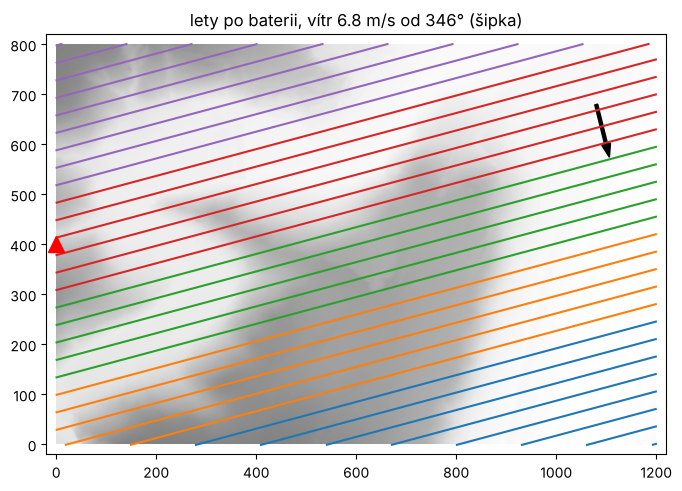

In [8]:
AZ = int(orient["čas (min)"].idxmin())   # ◀ parametr: azimut linek (°); výchozí je nejrychlejší z tabulky
E_BAT, TEMP, RESERVE = 77.0, 1.0, 0.20     # ◀ parametr: baterie (Wh), využitelná kapacita (v mrazu 0,7–0,8), rezerva při přistání
E_USE = E_BAT * TEMP * (1 - RESERVE)

def split(lines):
    """Rozdělí linky na lety: další linku přidá, jen když po ní zbude energie na návrat domů."""
    flights, cur, e, pos = [], [], 0.0, HOME
    for a, b in lines:
        need = (leg_time(pos, a) + leg_time(a, b) + 2 * T_TURN) * P_AVG / 3600
        if cur and e + need + leg_time(b, HOME) * P_AVG / 3600 > E_USE:
            flights.append((cur, e + leg_time(pos, HOME) * P_AVG / 3600))
            cur, e, pos = [], 0.0, HOME
            need = (leg_time(pos, a) + leg_time(a, b) + 2 * T_TURN) * P_AVG / 3600
        cur.append((a, b)); e += need; pos = b
    flights.append((cur, e + leg_time(pos, HOME) * P_AVG / 3600))
    return flights

fl = split(plan(AZ))
print(f"azimut {AZ}°, využitelná energie baterie {E_USE:.1f} Wh: {len(fl)} letů")
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.imshow(dmr, cmap="Greys", extent=(0, W, 0, Hh), alpha=0.5)
for k, (lines, e) in enumerate(fl):
    col = plt.cm.tab10(k % 10)
    for a, b in lines:
        ax.plot([a[0], b[0]], [a[1], b[1]], color=col, lw=1.5)
    print(f"let {k + 1}: {len(lines)} linek, {e:.1f} Wh")
ax.plot(*HOME, "r^", ms=12); ax.arrow(W - 120, Hh - 120, wvec[0] * 12, wvec[1] * 12, width=6, color="k")
ax.set(xlim=(-20, W + 20), ylim=(-20, Hh + 20), title=f"lety po baterii, vítr {WIND:.1f} m/s od {WDIR:.0f}° (šipka)"); plt.show()

> **✏️ Úkol 5.** Kolik letů mise potřebuje a proč mají lety různý počet linek? Přesuň místo vzletu `HOME` do středu území (600, 400) a spusť znovu buňky od načtení dat: ušetříš let? Nastav `TEMP = 0.75` jako v mrazu. Proč se při plánování počítá s návratem proti větru, i když vítr může během letu zeslábnout?

*Tvoje odpověď:* 

> **✏️ Rozšíření (nepovinné).** Nastav `LON, LAT` na svah nad Brněnskou přehradou (16.4798, 49.2467) nebo na údolí u Hosína u Hluboké nad Vltavou (14.4769, 49.0452), kde stoupá terén také od východu k západu, a porovnej pokrytí, vyhlazení a počet letů s Roztoky.

*Tvoje odpověď:* 

---
### Zdroje dat a literatura

- Digitální model reliéfu České republiky 5. generace (DMR 5G) a Digitální model povrchu České republiky 1. generace (DMP 1G), © ČÚZK, licence CC BY 4.0, služby https://ags.cuzk.cz/arcgis2/rest/services/dmr5g/ImageServer a https://ags.cuzk.cz/arcgis2/rest/services/dmp1g/ImageServer
- ČÚZK: *Technická zpráva k digitálnímu modelu povrchu České republiky 1. generace (DMP 1G)*, https://geoportal.cuzk.gov.cz/Dokumenty/TECHNICKA_ZPRAVA_DMP_1G.pdf (úplná střední chyba výšky 0,4 m pro budovy a 0,7 m pro vegetaci).
- Počasí: Open-Meteo.com (CC BY 4.0), https://open-meteo.com
- DJI: *Mavic 3 Enterprise, specifikace* (https://enterprise.dji.com/mavic-3-enterprise/specs): čip 4/3, 5280 × 3956 px, ohnisko 12,3 mm; stoupání 6 m/s a klesání 6 m/s v normálním režimu; výdrž 45 min; baterie 77 Wh.
- Výška letu v otevřené kategorii max. 120 m od nejbližšího bodu zemského povrchu: prováděcí nařízení Komise (EU) 2019/947, příloha, UAS.OPEN.010.

### Jak citovat

OpenSkyLab (2026). Plánovač letu, pokročilá verze: pokrytí snímky, sledování terénu, vítr a baterie [notebook, výukový materiál], verze 1.0. https://github.com/OpenSkyLab-space/notebooks/blob/main/flight_planner_pro_cs.ipynb. Licence CC BY 4.0.

Text a kód notebooku: OpenSkyLab, licence [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/). Data mají licence svých poskytovatelů (viz výše).

*Materiál připravil tým OpenSkyLab s pomocí generativní AI Claude (Anthropic), která pomáhala s návrhem kódu a textu. Za obsah odpovídají autoři.*